# Data cleaning - NTSB aviation cases

## Setup and loading

In [29]:
import json

import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

pd.set_option("display.max_colwidth", 200)

In [30]:
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

True

In [31]:
with open("ntsb_cases.json", encoding="utf-8") as file:
    raw_cases = json.load(file)

In [32]:
print("Number of cases:", len(raw_cases))

Number of cases: 99670


## Build the table

In [33]:
def clean_text(value):
    if isinstance(value, str) and value.strip() != "":
        return value.strip()
    return None

In [34]:
case_rows = []
for case in raw_cases:
    narratives = case.get("narratives") or []
    if len(narratives) > 0:
        narrative = narratives[0]
    else:
        narrative = {}

    aircraft_list = case.get("aircrafts") or []
    if len(aircraft_list) > 0:
        aircraft_category = aircraft_list[0].get("aircraftCategory")
    else:
        aircraft_category = None

    defining_events = []
    for aircraft in aircraft_list:
        for event in aircraft.get("events") or []:
            if event.get("isDefiningEvent"):
                defining_events.append(event)
    if len(defining_events) > 0:
        defining_category = defining_events[0].get("cicttEventSOEGroup")
    else:
        defining_category = None

    case_rows.append({
        "mKey": case.get("mKey"),
        "ntsbNumber": case.get("ntsbNumber"),
        "eventDate": case.get("eventDate"),
        "eventType": case.get("eventType"),
        "aircraftCategory": aircraft_category,
        "analysisNarrative": clean_text(narrative.get("analysisNarrative")),
        "numberOfDefiningEvents": len(defining_events),
        "definingCategory": defining_category,
    })

In [35]:
cases_table = pd.DataFrame(case_rows)

In [36]:
cases_table.shape

(99670, 8)

In [37]:
cases_table.head()

,mKey,ntsbNumber,eventDate,eventType,aircraftCategory,analysisNarrative,numberOfDefiningEvents,definingCategory
0,132162,FTW80DA029,1980-01-01,Accident,Airplane,NaN,0,NaN
1,131779,LAX80FUA07,1980-01-02,Accident,Airplane,NaN,0,NaN
2,131823,CHI80FEE13,1980-01-02,Accident,Airplane,NaN,0,NaN
3,131495,LAX80DVW09,1980-01-03,Accident,Airplane,NaN,0,NaN
4,131596,LAX80FVM12,1980-01-03,Accident,Airplane,NaN,0,NaN


## Cases with text

In [38]:
cases_table = cases_table[cases_table["analysisNarrative"].notna()]

In [39]:
print("Cases with analysisNarrative:", len(cases_table))

Cases with analysisNarrative: 83195


## Cases with one defining event

In [40]:
cases_table = cases_table[cases_table["numberOfDefiningEvents"] == 1]
cases_table = cases_table.rename(columns={"definingCategory": "label"})

In [41]:
print("Cases with one defining event:", len(cases_table))

Cases with one defining event: 23015


## Merge Unknown and Other labels


In [42]:
cases_table = cases_table.copy()
cases_table["label"] = cases_table["label"].replace({
    "Unknown": "Unknown/Other",
    "Other": "Unknown/Other",
})


In [43]:
print("Cases after merging Unknown and Other:", len(cases_table))


Cases after merging Unknown and Other: 23015


## Drop rare classes
Rare class is a class with <30 cases

In [44]:
MINIMUM_CASES_PER_CLASS = 30
label_counts = cases_table["label"].value_counts()
frequent_labels = label_counts[label_counts >= MINIMUM_CASES_PER_CLASS].index
cases_table = cases_table[cases_table["label"].isin(frequent_labels)]

In [45]:
print("Cases:", len(cases_table))
print("Classes:", cases_table["label"].nunique())

unknown_other_count = cases_table["label"].eq("Unknown/Other").sum()
unknown_other_percent = unknown_other_count / len(cases_table) * 100 if len(cases_table) else 0.0
print(f"Unknown/Other: {unknown_other_count} cases ({unknown_other_percent:.2f}% of all cleaned cases)")


Cases: 22863
Classes: 26
Unknown/Other: 1212 cases (5.30% of all cleaned cases)


In [46]:
cases_table["label"].value_counts()

label
Loss Of Control (Inflight)                   3972
Loss Of Control (Ground)                     3626
System/Component Failure (Powerplant)        3429
Abnormal Runway Contact                      3090
Fuel                                         1608
System/Component Failure (Non-Powerplant)    1230
Unknown/Other                                1212
Collision During Takeoff/Land                 657
CFIT                                          577
Low Altitude Operation/Event                  575
Runway Excursion                              539
Unintended Flight Into IMC                    305
Undershoot/Overshoot                          290
Turbulence                                    276
Ground Collision                              242
Fire                                          200
Birdstrike                                    200
Loss of Lift                                  165
Abrupt Maneuver                               160
Ground Handling                             

## Process text

In [47]:
STOPWORDS = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

In [48]:
def tokenize(text):
    text = text.lower().replace("’", "'").replace("-", " ").replace("/", " ")
    words = []
    for token in word_tokenize(text):
        if token == "n't":
            token = "not"
        if token.isalpha() and len(token) >= 2 and token not in STOPWORDS:
            words.append(token)
    return words

In [49]:
cases_table["tokens"] = cases_table["analysisNarrative"].apply(tokenize)

In [50]:
def lemmatize_words(words):
    lemmas = []
    for word in words:
        lemma = lemmatizer.lemmatize(word)
        if len(lemma) >= 2:
            lemmas.append(lemma)
    return " ".join(lemmas)

In [51]:
cases_table["text_lemmatized"] = cases_table["tokens"].apply(lemmatize_words)

In [52]:
for _, row in cases_table.sample(3, random_state=1).iterrows():
    print("ORIGINAL  :", row["analysisNarrative"][:300])
    print("LEMMATIZED:", row["text_lemmatized"][:300])
    print()

ORIGINAL  : The pilot reported that he was instructed by air traffic control to enter a right downwind following a corporate jet that was on final approach, and he was warned about wake turbulence. The pilot further stated that as he observed the jet pass by, he turned to watch it land so he could land beyond i
LEMMATIZED: pilot reported instructed air traffic control enter right downwind following corporate jet final approach warned wake turbulence pilot stated observed jet pas turned watch land could land beyond touchdown point pilot revealed interrupted completing landing checklist failed extend landing gear airpla

ORIGINAL  : Witnesses reported that, during the pilot’s initial approach for landing on runway 17, the experimental airplane was fast, encountered a wind gust, and ballooned, prompting the pilot to initiate a go-around. During the subsequent approach, one witness observed the nose landing gear nearly contact th
LEMMATIZED: witness reported pilot initial approach landing 

## Distribution of cleaned cases over time
Number of retained cases per event year. Years without cases are included with a count of zero.

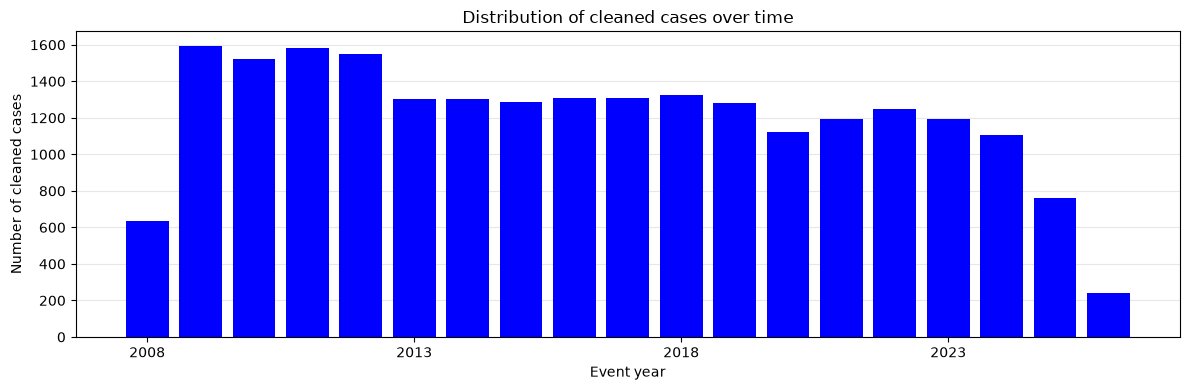

In [53]:
cleaned_event_dates = pd.to_datetime(cases_table["eventDate"], errors="coerce")
cleaned_cases_by_year = cleaned_event_dates.dt.year.dropna().astype(int).value_counts().sort_index()

if cleaned_cases_by_year.empty:
    print("No valid event dates available for the cleaned cases.")
else:
    years = range(cleaned_cases_by_year.index.min(), cleaned_cases_by_year.index.max() + 1)
    cleaned_cases_by_year = cleaned_cases_by_year.reindex(years, fill_value=0)

    figure, axis = plt.subplots(figsize=(12, 4))
    axis.bar(cleaned_cases_by_year.index, cleaned_cases_by_year.values, color="blue")
    axis.set_xlabel("Event year")
    axis.set_ylabel("Number of cleaned cases")
    axis.set_title("Distribution of cleaned cases over time")
    axis.set_xticks(list(years)[::5])
    axis.grid(axis="y", alpha=0.3)
    axis.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

missing_event_dates = cleaned_event_dates.isna().sum()
if missing_event_dates:
    print(f"Cases excluded from the plot due to missing or invalid event dates: {missing_event_dates}")


## Final checks and save

In [54]:
cases_table.shape

(22863, 10)

In [55]:
cases_table[["analysisNarrative", "text_lemmatized", "label"]].isna().sum()

analysisNarrative    0
text_lemmatized      0
label                0
dtype: int64

In [56]:
OUTPUT_COLUMNS = ["mKey", "ntsbNumber", "eventDate", "eventType", "aircraftCategory",
                  "label", "analysisNarrative", "text_lemmatized"]
cases_table[OUTPUT_COLUMNS].to_json("clean_cases.json", orient="records", force_ascii=False, indent=1)

In [57]:
print("Saved", len(cases_table), "cases to clean_cases.json")

Saved 22863 cases to clean_cases.json
